In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv(
    '/content/Sample - Superstore.csv',
    encoding='cp1252'
)

# Melihat 5 data pertama
display(df.head())

# Melihat ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Melihat informasi dataset
df.info()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Jumlah baris dan kolom: (9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          99

In [ ]:
# 1. Memeriksa missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Memeriksa jumlah data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

# 3. Memeriksa tipe data
print("\nTipe Data:")
print(df.dtypes)

# 4. Statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

# 5. Memeriksa nilai unik pada kolom kategori
categorical_columns = [
    'Ship Mode',
    'Segment',
    'Region',
    'Category',
    'Sub-Category'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Jumlah Data Duplikat:
0

Tipe Data:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: obj

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000



Ship Mode:
['Second Class' 'Standard Class' 'First Class' 'Same Day']

Segment:
['Consumer' 'Corporate' 'Home Office']

Region:
['South' 'West' 'Central' 'East']

Category:
['Furniture' 'Office Supplies' 'Technology']

Sub-Category:
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [ ]:
# Membuat salinan dataset asli
df_clean = df.copy()

# 1. Mengubah Order Date menjadi datetime
df_clean['Order Date'] = pd.to_datetime(
    df_clean['Order Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

# 2. Mengubah Ship Date menjadi datetime
df_clean['Ship Date'] = pd.to_datetime(
    df_clean['Ship Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

# 3. Mengubah Postal Code menjadi string
df_clean['Postal Code'] = (
    df_clean['Postal Code'].astype('string')
)

# 4. Memeriksa hasil perubahan tipe data
print("Tipe Data Setelah Cleaning:")
print(df_clean.dtypes)

# 5. Memeriksa apakah ada tanggal yang gagal dikonversi
print("\nTanggal Tidak Valid:")
print(df_clean[['Order Date', 'Ship Date']].isnull().sum())

# 6. Memeriksa apakah tanggal pengiriman
# lebih awal daripada tanggal pemesanan
invalid_shipping = (
    df_clean['Ship Date'] < df_clean['Order Date']
)

print("\nTanggal Pengiriman Tidak Valid:")
print(invalid_shipping.sum())

# 7. Memeriksa nilai numerik yang tidak wajar
print("\nPemeriksaan Nilai Numerik:")
print("Sales negatif:", (df_clean['Sales'] < 0).sum())
print("Quantity nol atau negatif:", (df_clean['Quantity'] <= 0).sum())
print("Discount di luar 0-1:",
      (~df_clean['Discount'].between(0, 1)).sum())

# 8. Melihat hasil akhir
display(df_clean.head())


Tipe Data Setelah Cleaning:
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code      string[python]
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

Tanggal Tidak Valid:
Order Date    0
Ship Date     0
dtype: int64

Tanggal Pengiriman Tidak Valid:
0

Pemeriksaan Nilai Numerik:
Sales negatif: 0
Quantity nol atau negatif: 0
Discount di luar 0-1: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
# Menghitung KPI utama

total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
total_orders = df_clean['Order ID'].nunique()
total_customers = df_clean['Customer ID'].nunique()
total_quantity = df_clean['Quantity'].sum()
profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS PERFORMANCE =====")
print(f"Total Sales      : ${total_sales:,.2f}")
print(f"Total Profit     : ${total_profit:,.2f}")
print(f"Total Orders     : {total_orders:,}")
print(f"Total Customers  : {total_customers:,}")
print(f"Total Quantity   : {total_quantity:,}")
print(f"Profit Margin    : {profit_margin:.2f}%")


===== BUSINESS PERFORMANCE =====
Total Sales      : $2,297,200.86
Total Profit     : $286,397.02
Total Orders     : 5,009
Total Customers  : 793
Total Quantity   : 37,873
Profit Margin    : 12.47%


In [ ]:
# Membuat kolom tahun
df_clean['Year'] = df_clean['Order Date'].dt.year

# Menghitung penjualan dan profit tahunan
yearly_sales = df_clean.groupby('Year').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

display(yearly_sales)


,Year,Total_Sales,Total_Profit
0,2014,484247.4981,49543.9741
1,2015,470532.5090,61618.6037
2,2016,609205.5980,81795.1743
3,2017,733215.2552,93439.2696


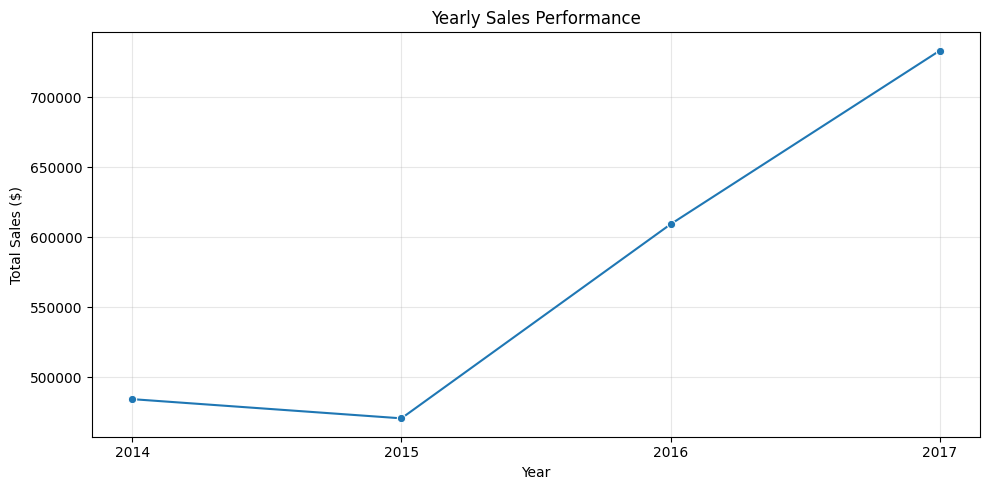

In [ ]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_sales,
    x='Year',
    y='Total_Sales',
    marker='o'
)

plt.title('Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales ($)')
plt.xticks(yearly_sales['Year'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Analisis berdasarkan kategori produk

category_analysis = df_clean.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

category_analysis['Profit_Margin'] = (
    category_analysis['Total_Profit'] /
    category_analysis['Total_Sales'] * 100
)

category_analysis = category_analysis.sort_values(
    by='Total_Sales',
    ascending=False
)

display(category_analysis.round(2))


,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
2,Technology,836154.03,145454.95,6939,1544,17.40
0,Furniture,741999.80,18451.27,8028,1764,2.49
1,Office Supplies,719047.03,122490.80,22906,3742,17.04


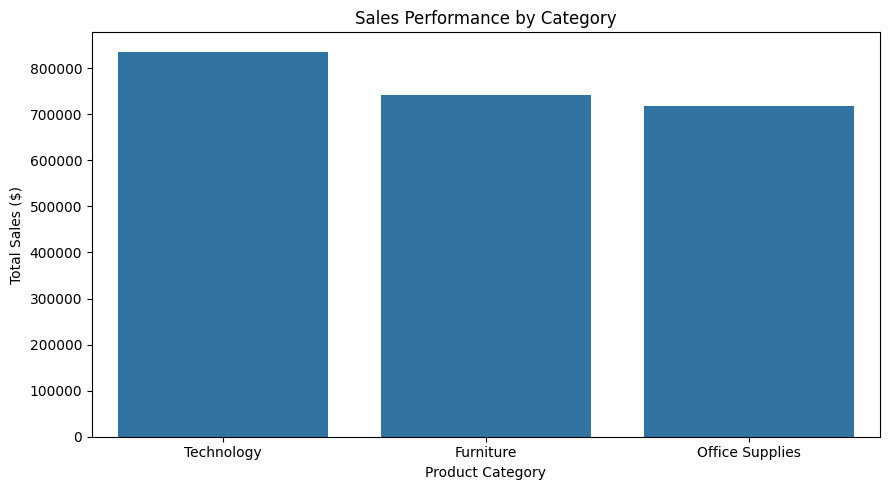

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x='Category',
    y='Total_Sales'
)

plt.title('Sales Performance by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()


In [ ]:
subcategory_analysis = df_clean.groupby(
    'Sub-Category'
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

subcategory_analysis = subcategory_analysis.sort_values(
    by='Total_Profit',
    ascending=False
)

display(subcategory_analysis.round(2))


,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
6,Copiers,149528.03,55617.82,234
13,Phones,330007.05,44515.73,3289
0,Accessories,167380.32,41936.64,2976
12,Paper,78479.21,34053.57,5178
3,Binders,203412.73,30221.76,5974
5,Chairs,328449.10,26590.17,2356
14,Storage,223843.61,21278.83,3158
1,Appliances,107532.16,18138.01,1729
9,Furnishings,91705.16,13059.14,3563
7,Envelopes,16476.40,6964.18,906


In [ ]:
loss_analysis = subcategory_analysis[
    subcategory_analysis['Total_Profit'] < 0
].sort_values(
    by='Total_Profit',
    ascending=True
)

print("5 Subkategori dengan Kerugian Terbesar:")

display(loss_analysis.head(5).round(2))


5 Subkategori dengan Kerugian Terbesar:


,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
16,Tables,206965.53,-17725.48,1241
4,Bookcases,114880.00,-3472.56,868
15,Supplies,46673.54,-1189.10,647


In [ ]:
# Mengelompokkan transaksi berdasarkan tingkat diskon

discount_analysis = df_clean.groupby('Discount').agg(
    Total_Transactions=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).reset_index()

display(discount_analysis.round(2))


,Discount,Total_Transactions,Total_Sales,Total_Profit,Average_Profit
0,0.00,4798,1087908.47,320987.60,66.90
1,0.10,94,54369.35,9029.18,96.06
2,0.15,52,27558.52,1418.99,27.29
3,0.20,3657,764594.37,90337.31,24.70
4,0.30,227,103226.66,-10369.28,-45.68
5,0.32,27,14493.46,-2391.14,-88.56
6,0.40,206,116417.78,-23057.05,-111.93
7,0.45,11,5484.97,-2493.11,-226.65
8,0.50,66,58918.54,-20506.43,-310.70
9,0.60,138,6644.70,-5944.66,-43.08


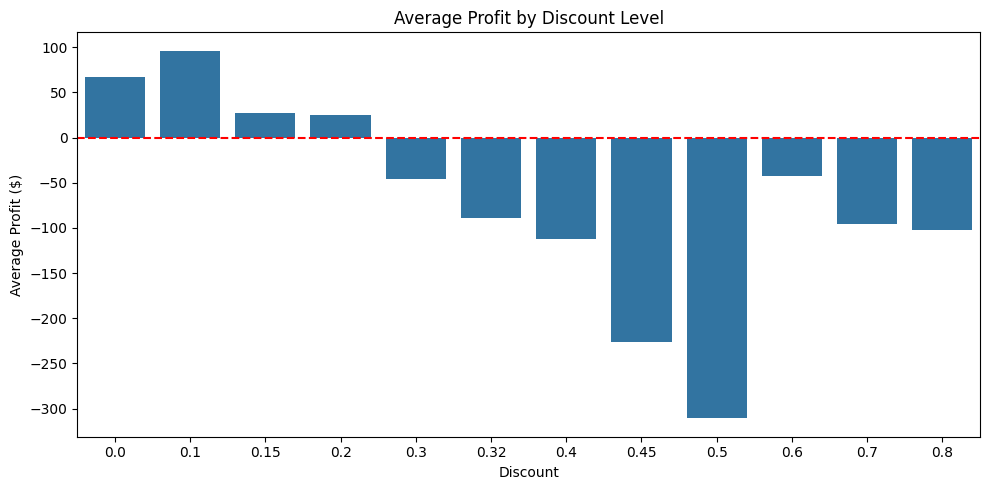

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x='Discount',
    y='Average_Profit'
)

plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit ($)')
plt.axhline(0, linestyle='--', color='red')
plt.tight_layout()
plt.show()


In [ ]:
# Analisis diskon pada subkategori Tables

tables_discount = df_clean[
    df_clean['Sub-Category'] == 'Tables'
].groupby('Discount').agg(
    Total_Transactions=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).reset_index()

display(tables_discount.round(2))


,Discount,Total_Transactions,Total_Sales,Total_Profit,Average_Profit
0,0.00,72,71578.76,13276.30,184.39
1,0.20,71,45430.23,-303.56,-4.28
2,0.30,54,25182.15,-3402.33,-63.01
3,0.40,75,45614.41,-16187.40,-215.83
4,0.45,11,5484.97,-2493.11,-226.65
5,0.50,36,13675.01,-8615.39,-239.32


In [ ]:
discount_category = df_clean.groupby(
    ['Category', 'Discount']
).agg(
    Total_Records=('Row ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).reset_index()

display(discount_category.round(2))


,Category,Discount,Total_Records,Total_Sales,Total_Profit,Average_Profit
0,Furniture,0.00,836,256025.27,58133.08,69.54
1,Furniture,0.10,76,46634.25,7111.01,93.57
2,Furniture,0.15,52,27558.52,1418.99,27.29
3,Furniture,0.20,615,216631.02,6265.95,10.19
4,Furniture,0.30,222,99470.35,-10695.32,-48.18
5,Furniture,0.32,27,14493.46,-2391.14,-88.56
6,Furniture,0.40,75,45614.41,-16187.40,-215.83
7,Furniture,0.45,11,5484.97,-2493.11,-226.65
8,Furniture,0.50,54,20983.47,-12871.20,-238.36
9,Furniture,0.60,138,6644.70,-5944.66,-43.08


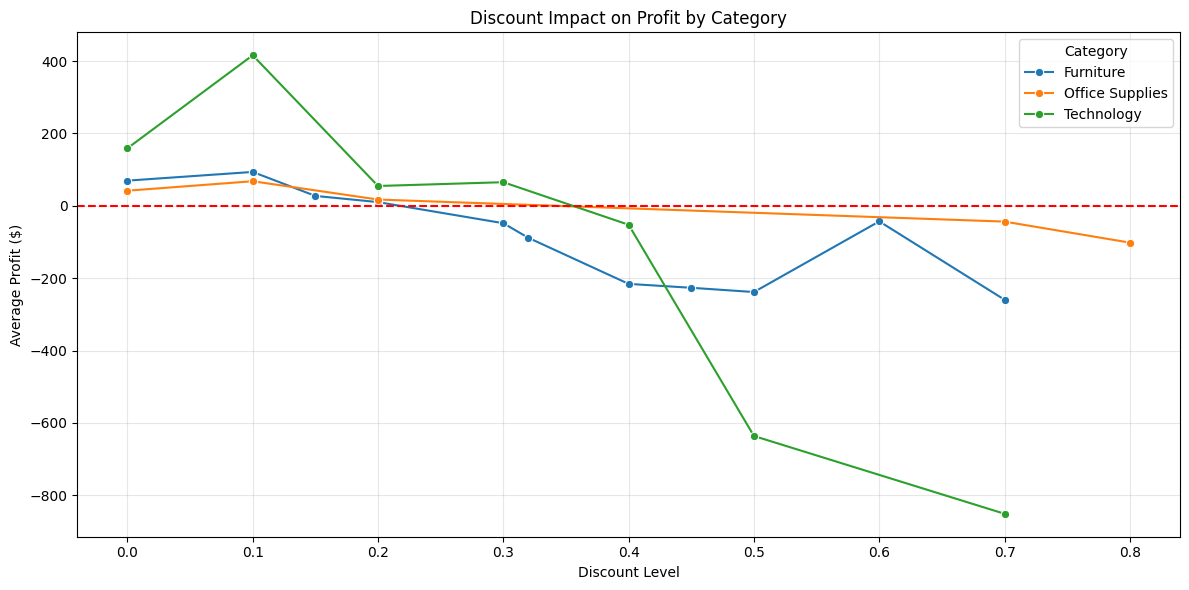

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=discount_category,
    x='Discount',
    y='Average_Profit',
    hue='Category',
    marker='o'
)

plt.axhline(0, color='red', linestyle='--')
plt.title('Discount Impact on Profit by Category')
plt.xlabel('Discount Level')
plt.ylabel('Average Profit ($)')
plt.legend(title='Category')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Total profit untuk transaksi dengan profit negatif
loss_records = df_clean[
    df_clean['Profit'] < 0
].copy()

loss_by_discount = loss_records.groupby('Discount').agg(
    Loss_Records=('Row ID', 'count'),
    Total_Loss=('Profit', 'sum')
).reset_index()

loss_by_discount = loss_by_discount.sort_values(
    by='Total_Loss'
)

display(loss_by_discount.round(2))


,Discount,Loss_Records,Total_Loss
9,0.70,418,-40075.36
10,0.80,300,-30539.04
5,0.40,180,-25787.83
7,0.50,66,-20506.43
2,0.20,502,-17258.07
3,0.30,208,-10777.69
8,0.60,138,-5944.66
6,0.45,11,-2493.11
4,0.32,27,-2391.14
1,0.15,17,-328.70


In [ ]:
# Menghitung persentase transaksi yang mengalami kerugian

loss_rate = df_clean.groupby('Discount').agg(
    Total_Records=('Row ID', 'count'),
    Loss_Records=('Profit', lambda x: (x < 0).sum())
).reset_index()

loss_rate['Loss_Rate'] = (
    loss_rate['Loss_Records'] /
    loss_rate['Total_Records'] * 100
)

display(loss_rate.round(2))


,Discount,Total_Records,Loss_Records,Loss_Rate
0,0.00,4798,0,0.00
1,0.10,94,4,4.26
2,0.15,52,17,32.69
3,0.20,3657,502,13.73
4,0.30,227,208,91.63
5,0.32,27,27,100.00
6,0.40,206,180,87.38
7,0.45,11,11,100.00
8,0.50,66,66,100.00
9,0.60,138,138,100.00


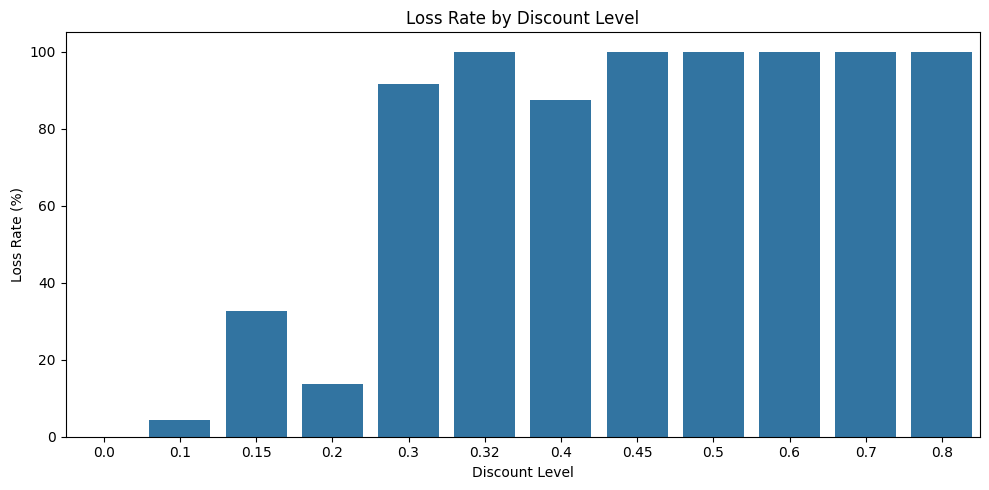

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=loss_rate,
    x='Discount',
    y='Loss_Rate'
)

plt.title('Loss Rate by Discount Level')
plt.xlabel('Discount Level')
plt.ylabel('Loss Rate (%)')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


In [ ]:
# Analisis performa berdasarkan wilayah

region_analysis = df_clean.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Total_Customers=('Customer ID', 'nunique')
).reset_index()

region_analysis['Profit_Margin'] = (
    region_analysis['Total_Profit'] /
    region_analysis['Total_Sales'] * 100
)

region_analysis = region_analysis.sort_values(
    by='Total_Profit',
    ascending=False
)

display(region_analysis.round(2))


,Region,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin
3,West,725457.82,108418.45,12266,1611,686,14.94
1,East,678781.24,91522.78,10618,1401,674,13.48
2,South,391721.90,46749.43,6209,822,512,11.93
0,Central,501239.89,39706.36,8780,1175,629,7.92


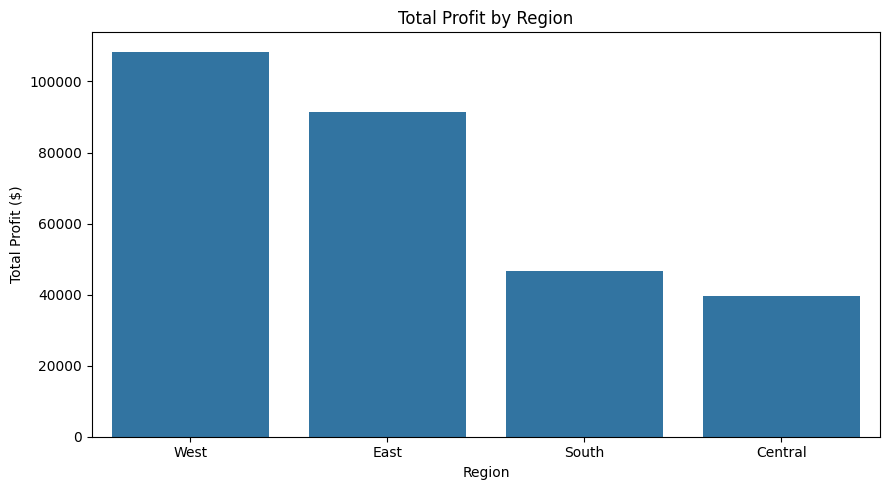

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_analysis,
    x='Region',
    y='Total_Profit'
)

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit ($)')
plt.tight_layout()
plt.show()


In [ ]:
# Analisis berdasarkan segmen pelanggan
segment_analysis = df_clean.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Total_Customers=('Customer ID', 'nunique')
).reset_index()

segment_analysis['Profit_Margin'] = (
    segment_analysis['Total_Profit'] /
    segment_analysis['Total_Sales'] * 100
)

segment_analysis = segment_analysis.sort_values(
    by='Total_Profit',
    ascending=False
)

display(segment_analysis.round(2))


,Segment,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin
0,Consumer,1161401.34,134119.21,19521,2586,409,11.55
1,Corporate,706146.37,91979.13,11608,1514,236,13.03
2,Home Office,429653.15,60298.68,6744,909,148,14.03


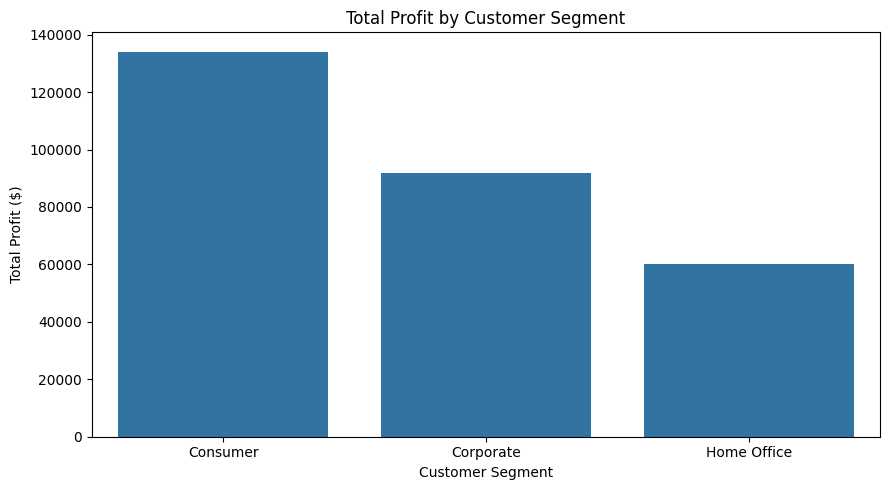

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis,
    x='Segment',
    y='Total_Profit'
)

plt.title('Total Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit ($)')
plt.tight_layout()
plt.show()


In [ ]:
city_analysis = df_clean.groupby('City').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Total_Customers=('Customer ID', 'nunique')
).reset_index()

city_analysis['Profit_Margin'] = (
    city_analysis['Total_Profit'] /
    city_analysis['Total_Sales'] * 100
)

# 10 kota dengan profit tertinggi
top_cities = city_analysis.sort_values(
    by='Total_Profit',
    ascending=False
).head(10)

display(top_cities.round(2))


,City,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin
329,New York City,256368.16,62036.98,450,355,24.20
266,Los Angeles,175851.34,30440.76,384,304,17.31
452,Seattle,119540.74,29156.10,212,188,24.39
438,San Francisco,112669.09,17507.39,265,232,15.54
123,Detroit,42446.94,13181.79,53,50,31.05
233,Lafayette,25036.20,10018.39,17,17,40.02
215,Jackson,24963.86,7581.68,37,35,30.37
21,Atlanta,17197.84,6993.66,17,17,40.67
300,Minneapolis,16870.54,6824.58,13,13,40.45
437,San Diego,47521.03,6377.20,88,86,13.42


In [ ]:
loss_cities = city_analysis[
    city_analysis['Total_Profit'] < 0
].sort_values(
    by='Total_Profit',
    ascending=True
).head(10)

print("10 Kota dengan Kerugian Terbesar:")

display(loss_cities.round(2))


10 Kota dengan Kerugian Terbesar:


,City,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin
374,Philadelphia,109077.01,-13837.77,265,239,-12.69
207,Houston,64504.76,-10153.55,188,172,-15.74
434,San Antonio,21843.53,-7299.05,27,27,-33.42
241,Lancaster,9891.46,-7239.07,27,26,-73.19
80,Chicago,48539.54,-6654.57,171,155,-13.71
60,Burlington,21668.08,-3622.88,15,14,-16.72
109,Dallas,20131.93,-2846.53,80,77,-14.14
375,Phoenix,11000.26,-2790.88,29,28,-25.37
24,Aurora,11656.48,-2691.74,35,34,-23.09
216,Jacksonville,44713.18,-2323.84,61,61,-5.20


In [ ]:
customer_analysis = df_clean.groupby(
    ['Customer ID', 'Customer Name']
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

# 10 pelanggan dengan profit tertinggi
top_customers = customer_analysis.sort_values(
    by='Total_Profit',
    ascending=False
).head(10)

display(top_customers.round(2))


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
741,TC-20980,Tamara Chand,19052.22,8981.32,5,42
621,RB-19360,Raymond Buch,15117.34,6976.10,6,71
669,SC-20095,Sanjit Chand,14142.33,5757.41,9,87
327,HL-15040,Hunter Lopez,12873.30,5622.43,6,50
6,AB-10105,Adrian Barton,14473.57,5444.81,10,73
730,TA-21385,Tom Ashbrook,14595.62,4703.79,4,36
160,CM-12385,Christopher Martinez,8954.02,3899.89,4,34
424,KD-16495,Keith Dawkins,8181.26,3038.63,12,84
48,AR-10540,Andy Reiter,6608.45,2884.62,6,33
234,DR-12940,Daniel Raglin,8350.87,2869.08,8,57


In [ ]:
bottom_customers = customer_analysis.sort_values(
    by='Total_Profit',
    ascending=True
).head(10)

print("10 Pelanggan dengan Profit Terendah:")

display(bottom_customers.round(2))

10 Pelanggan dengan Profit Terendah:


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
180,CS-12505,Cindy Stewart,5690.05,-6626.39,6,40
310,GT-14635,Grant Thornton,9351.21,-4108.66,3,26
459,LF-17185,Luke Foster,3930.51,-3583.98,7,69
711,SR-20425,Sharelle Roach,3233.48,-3333.91,5,34
322,HG-14965,Henry Goldwyn,3247.64,-2797.96,12,68
555,NC-18415,Nathan Cano,2218.99,-2204.81,6,38
666,SB-20290,Sean Braxton,8057.89,-2082.75,7,84
700,SM-20320,Sean Miller,25043.05,-1980.74,5,50
165,CP-12340,Christine Phan,5888.28,-1850.30,8,59
560,NF-18385,Natalie Fritzler,8322.83,-1695.97,7,52


In [2]:
# !pip install mysql-connector-python
# !pip install pymysql sqlalchemy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 45.0 MB/s  0:00:00


In [3]:
import getpass
import mysql.connector

conn = mysql.connector.connect(
    host="gateway01.ap-southeast-1.prod.aws.tidbcloud.com",
    port=4000,
    user="g7XusXjgXzGJdci.root",
    password=getpass.getpass("Masukkan password: "),
    database="superstore",
    ssl_verify_cert=True,
    ssl_verify_identity=True,
)

cursor = conn.cursor()

print("Berhasil terhubung kembali!")


Masukkan password: ··········
Berhasil terhubung kembali!


In [ ]:
create_table = """
CREATE TABLE IF NOT EXISTS superstore_sales (
    row_id INT PRIMARY KEY,
    order_id VARCHAR(30),
    order_date DATETIME,
    ship_date DATETIME,
    ship_mode VARCHAR(50),
    customer_id VARCHAR(30),
    customer_name VARCHAR(100),
    segment VARCHAR(50),
    country VARCHAR(100),
    city VARCHAR(100),
    state VARCHAR(100),
    postal_code VARCHAR(20),
    region VARCHAR(50),
    product_id VARCHAR(50),
    category VARCHAR(50),
    sub_category VARCHAR(50),
    product_name VARCHAR(255),
    sales DOUBLE,
    quantity INT,
    discount DOUBLE,
    profit DOUBLE
);
"""

cursor.execute(create_table)
conn.commit()

print("Tabel superstore_sales berhasil dibuat!")

Tabel superstore_sales berhasil dibuat!


In [ ]:
import pandas as pd

# Membuat salinan DataFrame tanpa kolom Year
df_upload = df_clean.drop(columns=['Year'], errors='ignore').copy()

# Memastikan jumlah kolom
print("Jumlah kolom:", len(df_upload.columns))
print("Shape:", df_upload.shape)

Jumlah kolom: 21
Shape: (9994, 21)


In [ ]:
import pandas as pd

# Mengubah nama kolom menjadi format SQL
# df_upload = df_clean.copy()

df_upload.columns = [
    'row_id', 'order_id', 'order_date', 'ship_date',
    'ship_mode', 'customer_id', 'customer_name',
    'segment', 'country', 'city', 'state',
    'postal_code', 'region', 'product_id',
    'category', 'sub_category', 'product_name',
    'sales', 'quantity', 'discount', 'profit'
]

# Memastikan tanggal sesuai format Python datetime
df_upload['order_date'] = pd.to_datetime(df_upload['order_date'])
df_upload['ship_date'] = pd.to_datetime(df_upload['ship_date'])

# Memastikan postal code berupa teks
df_upload['postal_code'] = df_upload['postal_code'].astype(str)

# Mengubah nilai pandas/numpy menjadi tipe Python
def convert_value(value):
    if pd.isna(value):
        return None
    if hasattr(value, 'to_pydatetime'):
        return value.to_pydatetime()
    if hasattr(value, 'item'):
        return value.item()
    return value

data = [
    tuple(convert_value(v) for v in row)
    for row in df_upload.itertuples(index=False, name=None)
]

columns = ', '.join(f'`{col}`' for col in df_upload.columns)
placeholders = ', '.join(['%s'] * len(df_upload.columns))

insert_query = f"""
INSERT INTO superstore_sales ({columns})
VALUES ({placeholders})
"""

# Kosongkan tabel khusus proyek ini sebelum memuat ulang
cursor.execute("TRUNCATE TABLE superstore_sales")

# Memasukkan data dalam batch
for i in range(0, len(data), 1000):
    cursor.executemany(insert_query, data[i:i+1000])

conn.commit()

print("Berhasil memasukkan", len(data), "baris data!")


Berhasil memasukkan 9994 baris data!


In [ ]:
cursor.execute("""
SELECT COUNT(*)
FROM superstore_sales;
""")

total_data = cursor.fetchone()[0]

print("Total baris data:", total_data)

Total baris data: 9994
